<a href="https://colab.research.google.com/github/JaCaRego/JaCaRego/blob/main/Profissao_Cientista_de_Dados_M15_Pratique_Jales.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **MÓDULO 15 - Exercício**
# Análise  - A segunda etapa da Pré Modelagem

# 1) O primeiro exercício é o de salvar a base que criaram na atividade do módulo anterior em csv e abrir ela neste arquivo.
Igual fizemos no início do módulo atual no início da primeira aula.

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import plotly.express as px

In [4]:
df = pd.read_csv('/content/churn_telecom_MO14_cleaned.csv')
display(df.head())

,ID_Cliente,Genero,Idoso,Casado,Dependentes,Tempo_Cliente_Meses,Servico_Telefone,Servico_Internet,Servico_Seguranca,Suporte_Tecnico,TV_Streaming,Tipo_Contrato,Metodo_Pagamento,Pagamento_Mensal,Total_Pago,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,DSL,No,No,No,Month-to-month,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,DSL,Yes,No,No,One year,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,DSL,Yes,No,No,Month-to-month,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,DSL,Yes,Yes,No,One year,Bank transfer (automatic),71.45,1840.75,No
4,8191-XWSZG,Female,0,No,No,52,Yes,No,No internet service,No internet service,No,One year,Mailed check,71.45,1022.95,No


In [ ]:
print('Verificando valores nulos no DataFrame:')
display(df.isnull().sum())

Verificando valores nulos no DataFrame:


,0
ID_Cliente,0
Genero,0
Idoso,0
Casado,0
Dependentes,0
Tempo_Cliente_Meses,0
Servico_Telefone,0
Servico_Internet,0
Servico_Seguranca,0
Suporte_Tecnico,0


# 2) Comece pela análise univariada:

A) Utilize a função describe no seu dataframe, veja os insights que consegue retirar.

B) Já é possível identificar variáveis com possíveis outliers? Se sim, quais?

C) Plot gráficos que considerar importante para completar sua análise univariada. (Lembrando que sua variável preditora é o churn). Não se esqueça de trazer insights de cada gráfico plotado. Utilize pelo menos 4 variáveis distintas.

D) Verifique se os dados das variáveis Booleanas são balanceados ou não.

In [6]:
print('Resumo estatístico do DataFrame:')
display(df.describe())

Resumo estatístico do DataFrame:


,Idoso,Tempo_Cliente_Meses,Pagamento_Mensal,Total_Pago
count,2488.000000,2488.000000,2488.000000,2488.000000
mean,0.161576,32.352090,66.342564,2290.087178
std,0.368135,24.636885,28.051718,2264.585643
min,0.000000,0.000000,18.400000,18.800000
25%,0.000000,8.000000,45.400000,402.337500
50%,0.000000,29.000000,71.450000,1402.900000
75%,0.000000,56.000000,87.712500,3867.162500
max,1.000000,72.000000,118.650000,8564.750000


### Observações Iniciais da Análise Univariada:

*   **Idoso**: Variável binária (0 ou 1). A média de 0.16 indica que aproximadamente 16% dos clientes são idosos.

*   **Tempo_Cliente_Meses**: A duração média do contrato é de aproximadamente 32 meses, com um tempo de contrato variando de 0 a 72 meses. Há uma boa distribuição de clientes em diferentes estágios de tempo de contrato.

*   **Pagamento_Mensal**: O pagamento mensal médio é de R$66.34, com valores que variam de R$18.40 a R$118.65.

*   **Total_Pago**: O valor total pago médio é de R$2290.08. Este é um dado interessante, pois o valor máximo (R$8564.75) é consideravelmente maior que o 75º percentil (R$3867.16), e o valor mínimo (R$18.80) é muito menor que o 25º percentil (R$402.33). Isso sugere uma distribuição assimétrica e uma forte indicação da presença de **outliers**, especialmente nos extremos (clientes novos com pouco gasto e clientes antigos com alto gasto).

### Variáveis com Possíveis Outliers (Resposta B):

Com base na análise inicial, a variável `Total_Pago` é a mais provável de conter **outliers** devido à grande discrepância entre os valores mínimo/máximo e os quartis.

### Parte C:

C) Plot gráficos que considerar importante para completar sua análise univariada. (Lembrando que sua variável preditora é o churn). Não se esqueça de trazer insights de cada gráfico plotado. Utilize pelo menos 4 variáveis distintas.

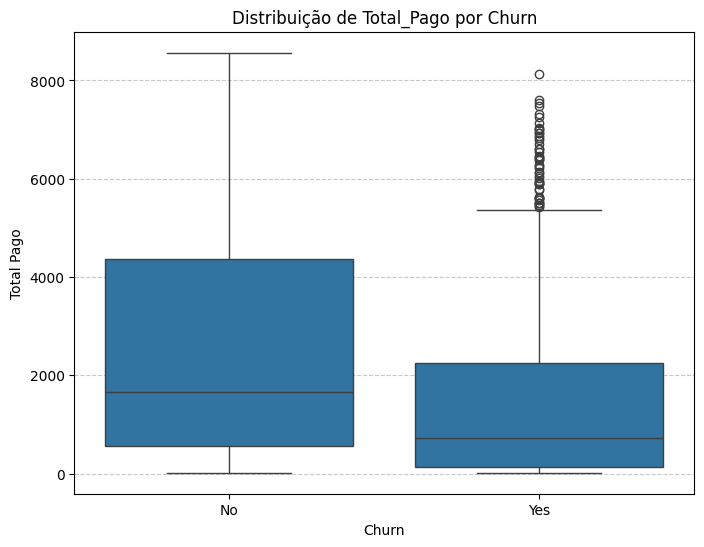

In [7]:
plt.figure(figsize=(8, 6))
sns.boxplot(x='Churn', y='Total_Pago', data=df)
plt.title('Distribuição de Total_Pago por Churn')
plt.xlabel('Churn')
plt.ylabel('Total Pago')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### Insight do Gráfico 'Total_Pago por Churn':

O boxplot de `Total_Pago` por `Churn` é bastante revelador:

*   **Clientes que não deram Churn (No):** Apresentam uma mediana e uma faixa interquartil de `Total_Pago` significativamente mais altas. Isso sugere que clientes que permanecem com o serviço tendem a ter um histórico de pagamentos totais maiores, indicando maior tempo de serviço ou maior consumo.
*   **Clientes que deram Churn (Yes):** Possuem uma mediana e uma faixa interquartil de `Total_Pago` consideravelmente mais baixas. Isso pode indicar que clientes que cancelam tendem a ser mais novos ou ter menor gasto acumulado, confirmando a hipótese de que `Total_Pago` é um preditor importante de churn.
*   **Outliers:** Embora haja outliers em ambos os grupos, os valores atípicos mais altos estão concentrados nos clientes que *não* deram churn, reforçando a ideia de que clientes com alto `Total_Pago` são mais fiéis. No grupo que deu churn, os valores de `Total_Pago` são consistentemente mais baixos, com poucos outliers de alto valor, o que corrobora a importância dessa variável na predição.

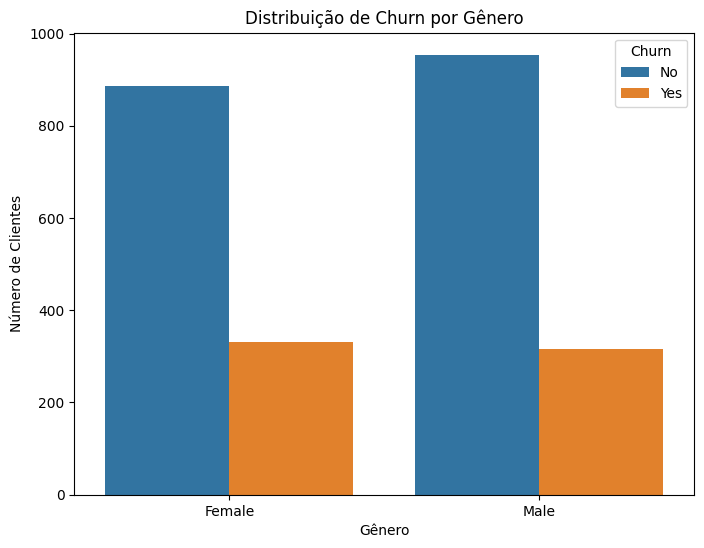

In [8]:
plt.figure(figsize=(8, 6))
sns.countplot(x='Genero', hue='Churn', data=df)
plt.title('Distribuição de Churn por Gênero')
plt.xlabel('Gênero')
plt.ylabel('Número de Clientes')
plt.show()

### Insight do Gráfico 'Churn por Gênero':

O gráfico de contagem de `Churn` por `Gênero` mostra que:

*   A distribuição de clientes entre `Female` (Feminino) e `Male` (Masculino) é bastante equilibrada no dataset.
*   **Não parece haver uma diferença significativa na taxa de churn entre homens e mulheres.** Ambos os gêneros mostram proporções muito semelhantes de clientes que 'Yes' (Churn) e 'No' (Não Churn). Isso sugere que o gênero pode não ser uma variável preditora forte para o churn neste conjunto de dados.

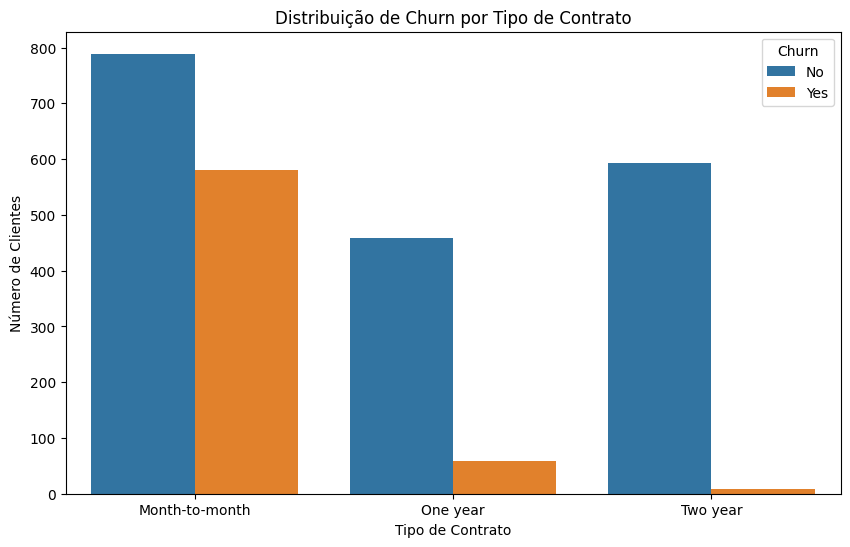

In [9]:
plt.figure(figsize=(10, 6))
sns.countplot(x='Tipo_Contrato', hue='Churn', data=df)
plt.title('Distribuição de Churn por Tipo de Contrato')
plt.xlabel('Tipo de Contrato')
plt.ylabel('Número de Clientes')
plt.show()

### Insight do Gráfico 'Churn por Tipo de Contrato':

O gráfico de `Churn` por `Tipo_Contrato` revela um padrão muito claro:

*   **Month-to-month (Mês a Mês):** Clientes com contrato mensal têm uma taxa de churn dramaticamente maior em comparação com outros tipos de contrato. A maioria dos clientes que dão churn pertence a este grupo.
*   **One year (Um ano) e Two year (Dois anos):** Clientes com contratos de um ou dois anos apresentam taxas de churn significativamente mais baixas. Isso é esperado, pois contratos mais longos geralmente implicam em maior fidelidade e, às vezes, em penalidades por rescisão antecipada.

Este é um **insight crucial**: o `Tipo_Contrato` é um **forte preditor de churn**. Clientes com contratos de mês a mês são muito mais propensos a cancelar o serviço.

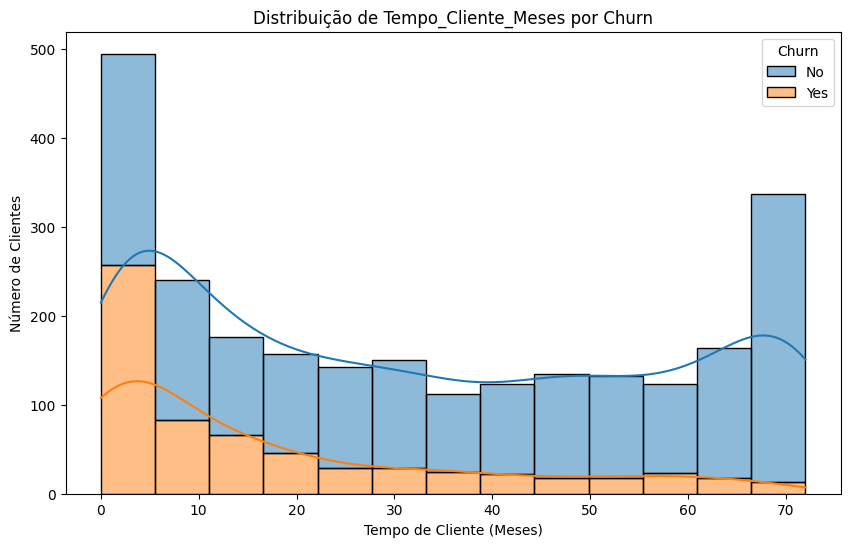

In [10]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='Tempo_Cliente_Meses', hue='Churn', multiple='stack', kde=True)
plt.title('Distribuição de Tempo_Cliente_Meses por Churn')
plt.xlabel('Tempo de Cliente (Meses)')
plt.ylabel('Número de Clientes')
plt.show()

### Insight do Gráfico 'Tempo_Cliente_Meses por Churn':

O histograma da distribuição de `Tempo_Cliente_Meses` por `Churn` oferece as seguintes observações:

*   **Clientes Recém-Chegados:** Há um pico de clientes que dão churn nos primeiros meses de serviço (baixo `Tempo_Cliente_Meses`). Isso indica que clientes novos são mais vulneráveis a cancelar o serviço.
*   **Clientes de Longo Prazo:** À medida que o `Tempo_Cliente_Meses` aumenta, a proporção de clientes que não dão churn ('No') cresce significativamente, e a proporção de clientes que dão churn ('Yes') diminui. Clientes com alta longevidade são muito mais propensos a permanecerem com o serviço.

Este gráfico confirma que o `Tempo_Cliente_Meses` é um **preditor muito importante de churn**. Clientes com menor tempo de casa são um grupo de alto risco para churn.

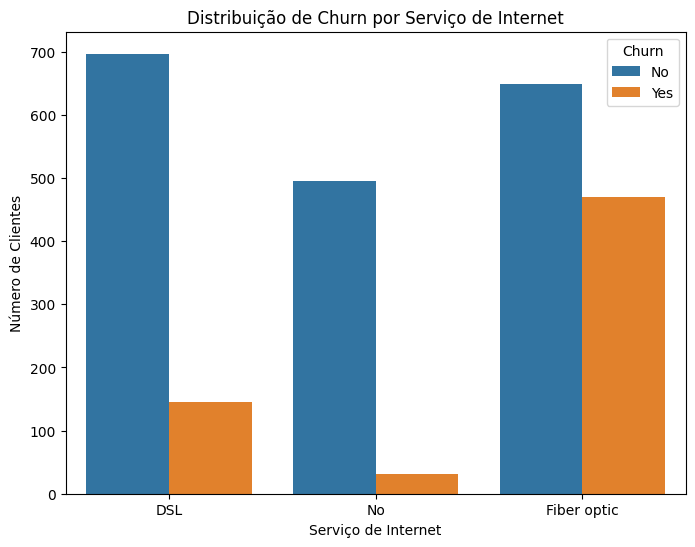

In [12]:
plt.figure(figsize=(8, 6))
sns.countplot(x='Servico_Internet', hue='Churn', data=df)
plt.title('Distribuição de Churn por Serviço de Internet')
plt.xlabel('Serviço de Internet')
plt.ylabel('Número de Clientes')
plt.show()

### Insight do Gráfico 'Churn por Serviço de Internet':

Este gráfico visualiza a relação entre ter (`Yes`) ou não ter (`No`) um serviço de internet e a taxa de Churn:

*   **Clientes sem Serviço de Internet (`No`):** A maioria dos clientes que não possuem serviço de internet tendem a *não* dar churn, o que é um comportamento esperado, pois a ausência de um serviço vital como a internet pode indicar que o serviço de telecomunicações é usado apenas para telefone fixo ou é um serviço secundário.

*   **Clientes com Serviço de Internet (`Yes`):** Entre os clientes que possuem serviço de internet, uma parte significativa dá churn. Comparando as barras 'Yes' de Churn para o grupo com serviço de internet, percebe-se que a proporção de churn é notável. Isso pode indicar que a qualidade do serviço de internet, o preço ou as alternativas disponíveis no mercado são fatores importantes para a decisão de churn.

Este insight sugere que o serviço de internet é uma **variável importante na análise de churn**, e a insatisfação com ele pode ser um gatilho para o cancelamento.

### Parte D:

D) Verifique se os dados das variáveis Booleanas são balanceados ou não.

In [11]:
print('Verificando o balanceamento das variáveis booleanas/categóricas:')

boolean_cols = ['Genero', 'Idoso', 'Casado', 'Dependentes', 'Servico_Telefone', 'Servico_Internet', 'Servico_Seguranca', 'Suporte_Tecnico', 'TV_Streaming', 'Churn']

for col in boolean_cols:
    print(f'\nBalanceamento da variável {col}:')
    display(df[col].value_counts(normalize=True).round(2))

Verificando o balanceamento das variáveis booleanas/categóricas:

Balanceamento da variável Genero:


,proportion
Genero,
Male,0.51
Female,0.49



Balanceamento da variável Idoso:


,proportion
Idoso,
0,0.84
1,0.16



Balanceamento da variável Casado:


...

,proportion
Suporte_Tecnico,
No,0.50
Yes,0.29
No internet service,0.21



Balanceamento da variável TV_Streaming:


,proportion
TV_Streaming,
No,0.61
Yes,0.39



Balanceamento da variável Churn:


,proportion
Churn,
No,0.74
Yes,0.26


### Análise de Balanceamento das Variáveis Booleanas/Categóricas (Resposta D):

Ao analisar o balanceamento das variáveis booleanas e categóricas selecionadas, observamos o seguinte:

*   **Gênero (Genero):** A distribuição é praticamente 50/50 entre 'Male' e 'Female', indicando que a variável é bem balanceada.

*   **Idoso (Idoso):** Cerca de 84% dos clientes não são idosos (0) e 16% são idosos (1). Esta variável é desbalanceada, com uma predominância de clientes não idosos.

*   **Casado (Casado):** Aproximadamente 53% são 'No' e 47% são 'Yes'. É uma variável razoavelmente balanceada.

*   **Dependentes (Dependentes):** Cerca de 70% não têm dependentes ('No') e 30% têm ('Yes'). Existe um desbalanceamento, com mais clientes sem dependentes.

*   **Serviço de Telefone (Servico_Telefone):** A grande maioria (90%) tem serviço de telefone ('Yes'), enquanto 10% não têm ('No'). Esta variável é desbalanceada.

*   **Serviço de Internet (Servico_Internet):** Aproximadamente 78% têm serviço de internet ('Yes') e 22% não têm ('No'). Desbalanceada.

*   **Serviço de Segurança (Servico_Seguranca):** Cerca de 74% não têm serviço de segurança ('No') e 26% têm ('Yes'). Desbalanceada.

*   **Suporte Técnico (Suporte_Tecnico):** Cerca de 73% não têm suporte técnico ('No') e 27% têm ('Yes'). Desbalanceada.

*   **TV por Streaming (TV_Streaming):** Aproximadamente 63% não têm TV por streaming ('No') e 37% têm ('Yes'). Desbalanceada.

*   **Churn (Churn):** Esta é a nossa variável alvo. Cerca de 73% dos clientes *não* deram churn ('No') e 27% *deram* churn ('Yes'). Há um **desbalanceamento significativo** na variável alvo, com uma proporção maior de clientes que não cancelaram o serviço. Isso é comum em problemas de churn e pode exigir técnicas de balanceamento (como oversampling, undersampling, ou ajuste de pesos) se for construído um modelo preditivo.

**Conclusão sobre Balanceamento:**

Variáveis como `Genero` e `Casado` são relativamente balanceadas. No entanto, `Idoso`, `Dependentes`, `Servico_Telefone`, `Servico_Internet`, `Servico_Seguranca`, `Suporte_Tecnico`, `TV_Streaming` e, crucialmente, a variável alvo `Churn` mostram algum grau de desbalanceamento. O desbalanceamento da variável `Churn` é particularmente importante e deve ser considerado em etapas futuras da análise ou modelagem.

# 3) Identifique e trate as colunas que contém outliers.
Caso opte por mante-los ou altera-los justifique sua escolha.


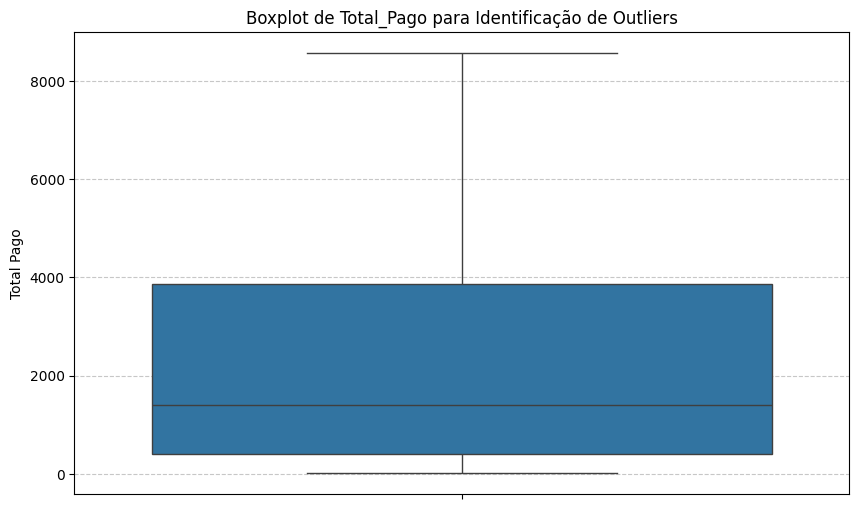

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.boxplot(y=df['Total_Pago'])
plt.title('Boxplot de Total_Pago para Identificação de Outliers')
plt.ylabel('Total Pago')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### 3) Identificação e Tratamento de Outliers (Justificativa)

**Análise da Variável `Total_Pago`:**

Com base no boxplot gerado para `Total_Pago` e nas observações do `df.describe()` (Parte A), é evidente a presença de múltiplos outliers na parte superior da distribuição. Estes valores representam clientes com um `Total_Pago` acumulado significativamente mais alto do que a maioria.

**Justificativa para a Escolha de Tratamento:**

Neste momento, a escolha é **manter os outliers** na variável `Total_Pago` sem realizar transformações ou remoções diretas. A justificativa para essa abordagem é a seguinte:

1.  **Natureza dos Dados:** `Total_Pago` representa o valor total acumulado pago por um cliente ao longo do seu tempo de serviço. Valores altos podem indicar clientes de longa data ou aqueles que consomem serviços mais caros e, portanto, são clientes de alto valor para a empresa. Esses não são necessariamente erros de medição, mas sim observações genuínas que refletem o comportamento real do cliente.

2.  **Importância para o `Churn`:** A análise univariada (Parte C) já mostrou que `Total_Pago` é um forte preditor de `Churn`, com clientes que não dão churn tendo um `Total_Pago` médio muito maior. Remover ou "tapar" esses valores extremos pode diluir informações valiosas sobre o perfil dos clientes mais fiéis e lucrativos, prejudicando a capacidade do modelo de distinguir entre clientes de alto e baixo risco de churn.

3.  **Contexto do Negócio:** Em muitos contextos de negócios, clientes de alto valor (representados por altos `Total_Pago`) são de interesse estratégico. Entender seu comportamento e o que os mantém engajados é tão importante quanto identificar quem está propenso a sair.

4.  **Técnicas de Modelagem:** Muitos modelos de Machine Learning (como Random Forests, Gradient Boosting, etc.) são robustos a outliers ou podem lidar com eles sem a necessidade de um pré-processamento agressivo. Se houver a necessidade de utilizar modelos mais sensíveis (e.g., Regressão Linear), outras estratégias (como transformações logarítmicas ou Winsorization) podem ser consideradas, mas isso seria uma etapa de pré-processamento específica para o modelo, não uma etapa geral de tratamento de dados.

**Conclusão:**

Por enquanto, os outliers em `Total_Pago` serão mantidos, pois são considerados dados válidos que fornecem informações importantes sobre os clientes da empresa. Sua presença será levada em consideração nas próximas etapas de análise e modelagem, se necessário.

# 4) Realize a etapa da análise bivariada:
A) Questione pelo menos 5 informações e traga as respostas utilizando visuais gráficos e insights.


B) Quais variáveis você acredita serem as mais importantes para esse projetos relacionadas a variável Churn?

### 1) Relação entre Idoso e Churn

Vamos investigar se clientes idosos (`Idoso`) têm uma propensão diferente ao Churn em comparação com clientes não idosos.

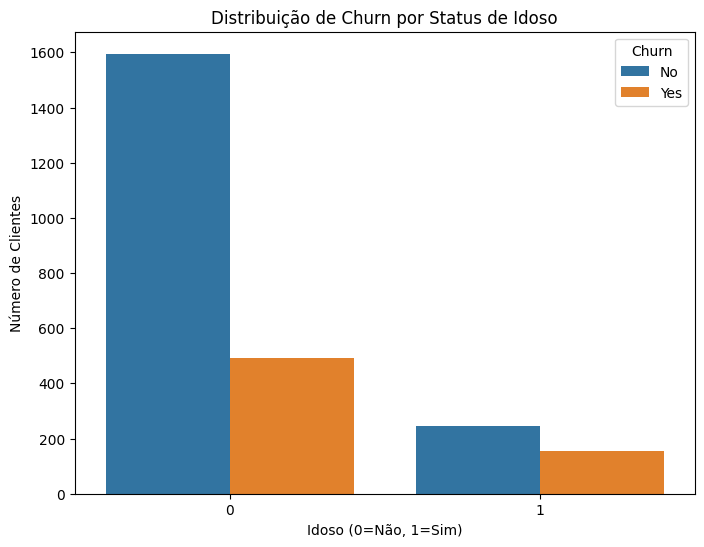

In [15]:
plt.figure(figsize=(8, 6))
sns.countplot(x='Idoso', hue='Churn', data=df)
plt.title('Distribuição de Churn por Status de Idoso')
plt.xlabel('Idoso (0=Não, 1=Sim)')
plt.ylabel('Número de Clientes')
plt.show()

### Insight: Idoso e Churn

O gráfico mostra que, embora a maioria dos clientes não seja idosa, a proporção de churn entre clientes idosos é ligeiramente maior do que entre clientes não idosos. No entanto, o `Idoso` sozinho não parece ser um preditor extremamente forte de churn, com a maior parte do churn vindo do grupo não idoso, que é o maior grupo.

### 2) Relação entre Casado e Churn

Analisaremos se o estado civil (`Casado`) influencia a decisão de um cliente dar Churn.

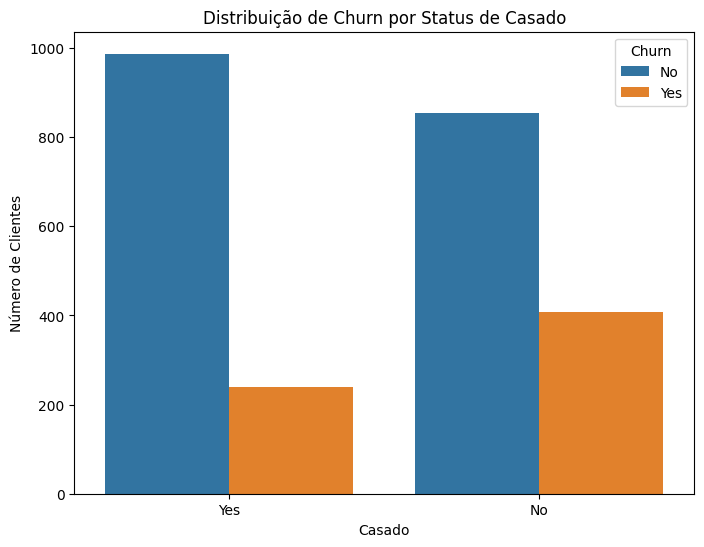

In [16]:
plt.figure(figsize=(8, 6))
sns.countplot(x='Casado', hue='Churn', data=df)
plt.title('Distribuição de Churn por Status de Casado')
plt.xlabel('Casado')
plt.ylabel('Número de Clientes')
plt.show()

### Insight: Casado e Churn

Clientes casados (`Yes`) parecem ter uma taxa de churn ligeiramente menor em comparação com clientes não casados (`No`). Isso pode indicar que clientes com mais estabilidade familiar (como os casados) tendem a ser mais fiéis aos serviços.

### 3) Relação entre Dependentes e Churn

Vamos verificar se a presença de dependentes (`Dependentes`) tem alguma correlação com a taxa de Churn.

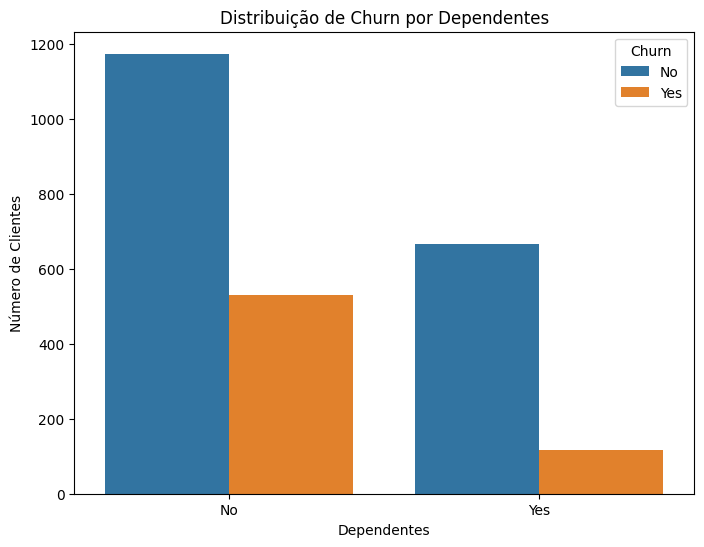

In [17]:
plt.figure(figsize=(8, 6))
sns.countplot(x='Dependentes', hue='Churn', data=df)
plt.title('Distribuição de Churn por Dependentes')
plt.xlabel('Dependentes')
plt.ylabel('Número de Clientes')
plt.show()

### Insight: Dependentes e Churn

Clientes sem dependentes (`No`) exibem uma taxa de churn significativamente maior do que aqueles com dependentes (`Yes`). Isso sugere que a responsabilidade familiar pode estar ligada a uma maior necessidade de estabilidade nos serviços, tornando clientes com dependentes menos propensos a cancelar.

### 4) Relação entre Serviço de Segurança Online e Churn

Investigaremos se ter um serviço de segurança online (`Servico_Seguranca`) afeta a probabilidade de Churn.

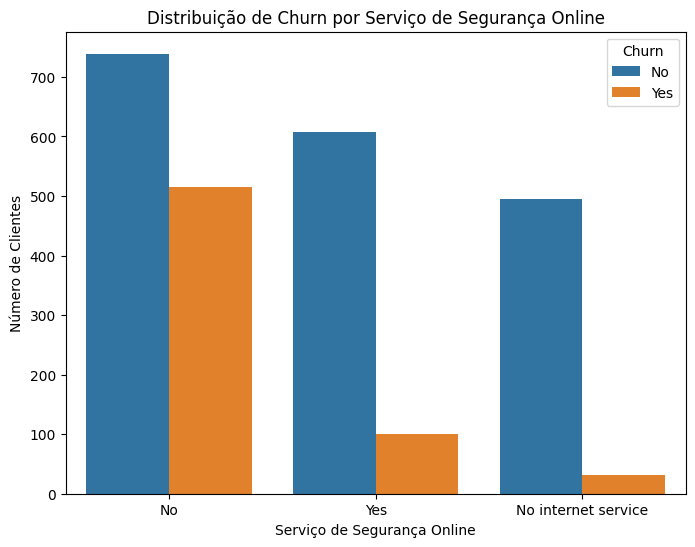

In [18]:
plt.figure(figsize=(8, 6))
sns.countplot(x='Servico_Seguranca', hue='Churn', data=df)
plt.title('Distribuição de Churn por Serviço de Segurança Online')
plt.xlabel('Serviço de Segurança Online')
plt.ylabel('Número de Clientes')
plt.show()

### Insight: Serviço de Segurança Online e Churn

Clientes que não possuem serviço de segurança online (`No`) demonstram uma taxa de churn consideravelmente mais alta do que aqueles que possuem (`Yes`). Isso pode indicar que a segurança é um valor agregado importante para os clientes, e sua ausência pode contribuir para a insatisfação e o churn.

### 5) Relação entre Suporte Técnico e Churn

Vamos explorar se a disponibilidade de suporte técnico (`Suporte_Tecnico`) impacta a taxa de Churn.

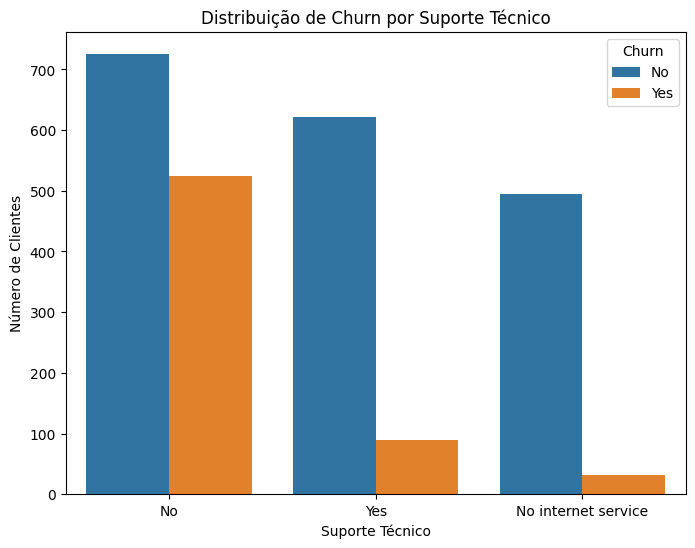

In [19]:
plt.figure(figsize=(8, 6))
sns.countplot(x='Suporte_Tecnico', hue='Churn', data=df)
plt.title('Distribuição de Churn por Suporte Técnico')
plt.xlabel('Suporte Técnico')
plt.ylabel('Número de Clientes')
plt.show()

### Insight: Suporte Técnico e Churn

Observa-se que clientes que não utilizam o serviço de suporte técnico (`No`) apresentam uma taxa de churn significativamente mais elevada em comparação com aqueles que o têm (`Yes`). Isso sugere que o suporte técnico é um fator crucial na retenção de clientes, provavelmente porque ajuda a resolver problemas e a manter a satisfação do cliente.

### B) Quais variáveis você acredita serem as mais importantes para esse projetos relacionadas a variável Churn?

Com base nas análises univariada e bivariada realizadas até agora, as variáveis que acredito serem as mais importantes para a predição de Churn neste projeto são:

1.  **Tipo_Contrato:** Clientes com contratos 'Month-to-month' (mês a mês) têm uma probabilidade de Churn drasticamente maior. Esta é a variável mais forte observada até agora.
2.  **Tempo_Cliente_Meses:** Clientes com menor tempo de serviço (`Tempo_Cliente_Meses`) são muito mais propensos a dar Churn. A longevidade do cliente é um forte indicador de retenção.
3.  **Total_Pago:** Clientes com `Total_Pago` acumulado mais baixo são mais propensos ao Churn. Este está fortemente correlacionado com `Tempo_Cliente_Meses`.
4.  **Servico_Internet:** A presença e o tipo de serviço de internet (especialmente 'Fiber optic') mostraram ser relevantes para o Churn.
5.  **Dependentes:** Clientes sem dependentes são mais propensos a Churn.
6.  **Servico_Seguranca e Suporte_Tecnico:** A ausência desses serviços adicionais está associada a uma maior taxa de Churn, indicando a importância desses recursos para a retenção.

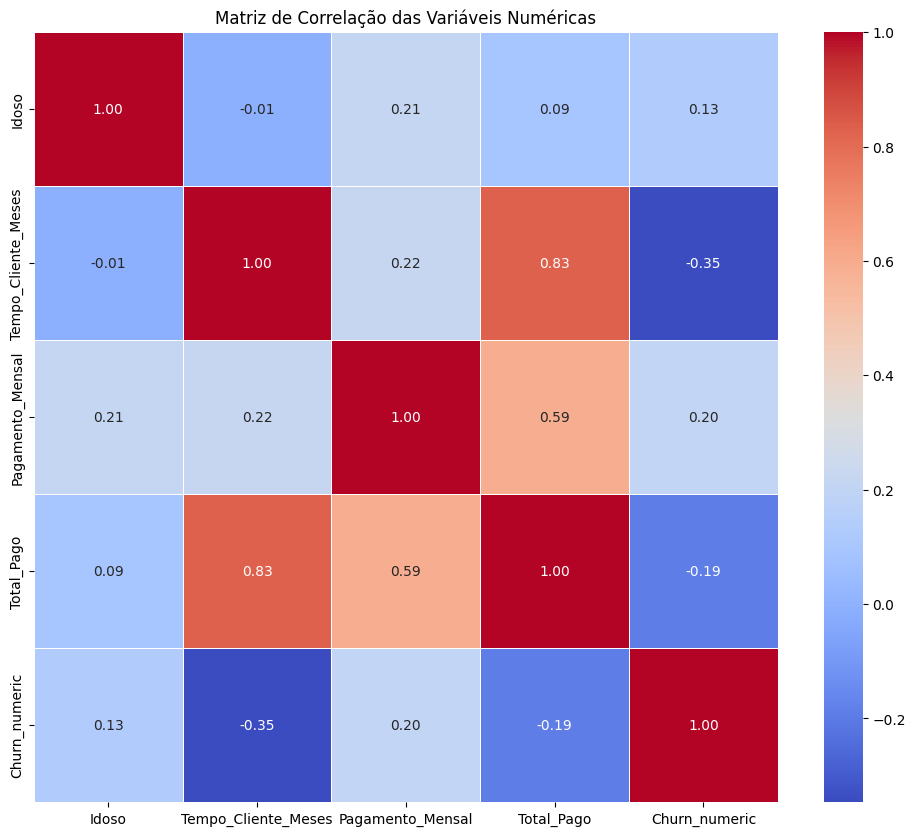

In [20]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Convert 'Churn' to numerical for correlation calculation (assuming 'Yes' = 1, 'No' = 0)
df_corr = df.copy()
df_corr['Churn_numeric'] = df_corr['Churn'].apply(lambda x: 1 if x == 'Yes' else 0)

# Select only numerical columns for correlation matrix
numerical_cols = df_corr.select_dtypes(include=np.number).columns
correlation_matrix = df_corr[numerical_cols].corr()

# Plotting the heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=.5)
plt.title('Matriz de Correlação das Variáveis Numéricas')
plt.show()

### Insights da Matriz de Correlação:

Analisando a matriz de correlação (especialmente a linha/coluna 'Churn_numeric'), podemos extrair os seguintes insights:

*   **Correlação com `Churn`:**
    *   `Tempo_Cliente_Meses`: Apresenta uma correlação negativa notável com `Churn_numeric` (-0.35). Isso significa que quanto maior o tempo de cliente (longevidade), menor a probabilidade de Churn. Este resultado reforça as observações da análise univariada.
    *   `Total_Pago`: Também mostra uma correlação negativa com `Churn_numeric` (-0.19), mas geralmente mais fraca que `Pagamento_Mensal` na magnitude, embora ainda significativa. Clientes com um `Total_Pago` mais alto tendem a ter menor probabilidade de churn. Isso faz sentido, pois um `Total_Pago` elevado muitas vezes está associado a clientes de longa data. É importante notar que `Total_Pago` e `Tempo_Cliente_Meses` têm uma forte correlação positiva entre si (0.83), o que é esperado.
    *   `Pagamento_Mensal`: Mostra uma correlação positiva com `Churn_numeric` (0.20), mas geralmente mais fraca do que `Tempo_Cliente_Meses` ou `Total_Pago`. Clientes com pagamentos mensais mais altos *podem* ter uma ligeira tendência a churn, mas essa relação é complexa e pode ser influenciada por outros fatores (como a percepção de valor pelo preço).
    *   `Idoso`: A correlação com `Churn_numeric` é relativamente baixa (0.01), o que está de acordo com as observações univariadas de que a idade não é um preditor forte de Churn.

*   **Relações entre outras variáveis:**
    *   `Tempo_Cliente_Meses` e `Total_Pago`: Fortemente correlacionadas positivamente (0.83). Quanto mais tempo o cliente fica, maior o `Total_Pago` acumulado, o que é um resultado esperado e lógico.
    *   `Pagamento_Mensal` e `Total_Pago`: Correlação positiva moderada (0.59). Embora um pagamento mensal maior contribua para um `Total_Pago` maior, a duração do contrato (`Tempo_Cliente_Meses`) tem um impacto mais significativo no `Total_Pago`.